# Model 1: Pothole detector (YOLO26-nano)

Detects potholes in road photos. This is stage 1 of a two-stage pipeline; stage 2 (`severity_classifier.ipynb`) rates how severe each detected pothole is, and `pipeline.ipynb` / `live.py` combine both.

**Setup**
- Dataset: [Potholes Detection (Roboflow Universe)](https://universe.roboflow.com/project-ssayl/potholes-detection-d4rma/dataset/1), CC BY 4.0, 13,767 images, one class (`pothole`)
- Model: YOLO26-nano (`yolo26n.pt`), 50 epochs, image size 640, batch 16, RTX 4060 Laptop GPU

**Results** (best epoch)
- Validation set (1,808 images): mAP50 0.84, mAP50-95 0.52
- Test set (890 images): mAP50 0.833, mAP50-95 0.528

**Known weakness:** the dataset has no negative examples (images without potholes), so at a low confidence threshold the model can flag dark shadows or vegetation as potholes. Using `conf=0.5` avoids this on my test photos.

**To run:** a free Roboflow API key is needed to download the dataset (you will be asked to type it in step 2).

## 1. Check the GPU

In [ ]:
import torch; print(torch.cuda.is_available())

True


## 2. Download the dataset
The key is requested with `getpass`, so it is not stored in the notebook.

In [ ]:
!pip install -q roboflow
from getpass import getpass
from roboflow import Roboflow

# The API key is typed when you run the cell, so it is never saved in the notebook.
rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("project-ssayl").project("potholes-detection-d4rma")
version = project.version(1)
dataset = version.download("yolo26")

## 3. Look at the folder structure

In [ ]:
import os
for root, dirs, files in os.walk("Potholes-Detection-1"):
    level = root.replace("Potholes-Detection-1", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 2:
        for f in files[:3]:
            print(f"{indent}  {f}")

Potholes-Detection-1/
  data.yaml
  README.dataset.txt
  README.roboflow.txt
  test/
    images/
    labels/
  train/
    images/
    labels/
  valid/
    images/
    labels/


## 4. Fix `data.yaml`
The downloaded file uses `../train/images` paths and the class name `'0'`. I rewrite it with paths relative to the dataset folder and the real class name `pothole`.

In [ ]:
with open("Potholes-Detection-1/data.yaml") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['0']

roboflow:
  workspace: project-ssayl
  project: potholes-detection-d4rma
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/project-ssayl/potholes-detection-d4rma/dataset/1


In [ ]:
yaml_content = """train: train/images
val: valid/images
test: test/images

nc: 1
names: ['pothole']
"""

with open("Potholes-Detection-1/data.yaml", "w") as f:
    f.write(yaml_content)

print("Updated data.yaml:")
with open("Potholes-Detection-1/data.yaml") as f:
    print(f.read())

Updated data.yaml:
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['pothole']



## 5. Check the labels
Draw the ground-truth boxes on 4 random training images to make sure the labels line up with the potholes.

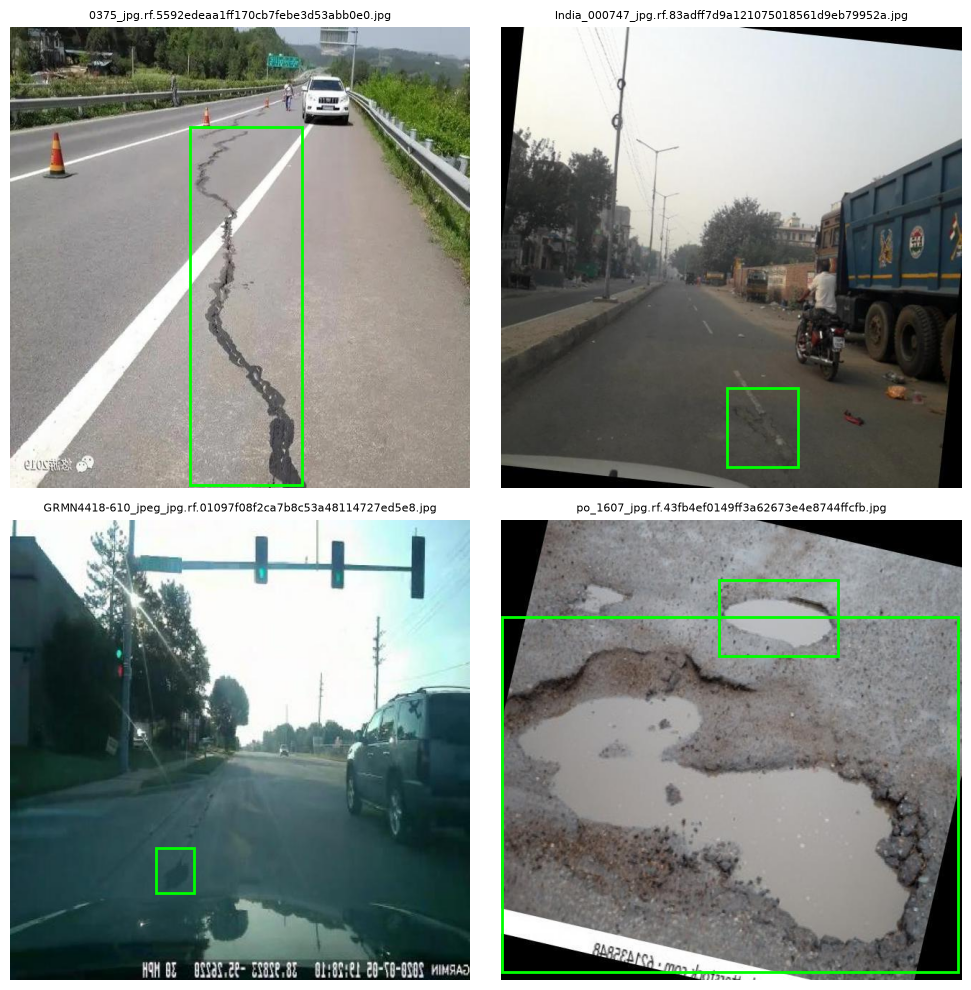

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os
import random

images_dir = "Potholes-Detection-1/train/images"
labels_dir = "Potholes-Detection-1/train/labels"

# Pick 4 random images to check
sample_files = random.sample(os.listdir(images_dir), 4)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, filename in zip(axes.flat, sample_files):
    img_path = os.path.join(images_dir, filename)
    label_path = os.path.join(labels_dir, filename.rsplit(".", 1)[0] + ".txt")

    img = Image.open(img_path)
    w, h = img.size
    ax.imshow(img)

    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                cls, x_center, y_center, box_w, box_h = map(float, line.split())
                # Convert normalized YOLO format to pixel corner coordinates
                x1 = (x_center - box_w / 2) * w
                y1 = (y_center - box_h / 2) * h
                rect = patches.Rectangle((x1, y1), box_w * w, box_h * h,
                                          linewidth=2, edgecolor='lime', facecolor='none')
                ax.add_patch(rect)

    ax.set_title(filename, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Train
Training ran on the GPU for up to 50 epochs and was interrupted once, so I resumed it from `last.pt` in the next cell (the resume cell is only needed if training stops early). Weights are saved to `runs/detect/pothole_runs/v1/weights/best.pt`.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt") 
results = model.train(
    data="Potholes-Detection-1/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,      
    project="pothole_runs",
    name="v1",
)

### Resume an interrupted run

In [1]:
from ultralytics import YOLO

model = YOLO("runs/detect/pothole_runs/v1/weights/last.pt")
results = model.train(resume=True)

Validating runs\detect\pothole_runs\v1\weights\best.pt...
Ultralytics 8.4.157  Python-3.13.3 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 57/57 6.6it/s 8.6s0.1s
                   all       1808       4487      0.877      0.767       0.84      0.524
Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to runs\detect\pothole_runs\v1


## 7. Evaluate on the test set
One test image has a label file mixing segmentation and detection rows, so Ultralytics ignores it (890 of 891 images are scored).

In [2]:
from ultralytics import YOLO

model = YOLO("runs/detect/pothole_runs/v1/weights/best.pt")
metrics = model.val(data="Potholes-Detection-1/data.yaml", split="test")

print(f"Test mAP50: {metrics.box.map50:.3f}")
print(f"Test mAP50-95: {metrics.box.map:.3f}")

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 7.1it/s 7.9s0.1s
                   all        890       2163      0.848      0.785      0.833      0.528
Test mAP50: 0.833
Test mAP50-95: 0.528


Test results (890 images): precision 0.85, recall 0.79, mAP50 0.833, mAP50-95 0.528. In plain words: about 85% of the boxes the model draws are real potholes, and it finds about 79% of the real potholes. mAP50 is the standard single score (a box counts as correct if it overlaps the true box by at least 50%). mAP50-95 is stricter, averaging over overlaps from 50% to 95%, which is why it’s lower.

## 8. Try the model on random test images

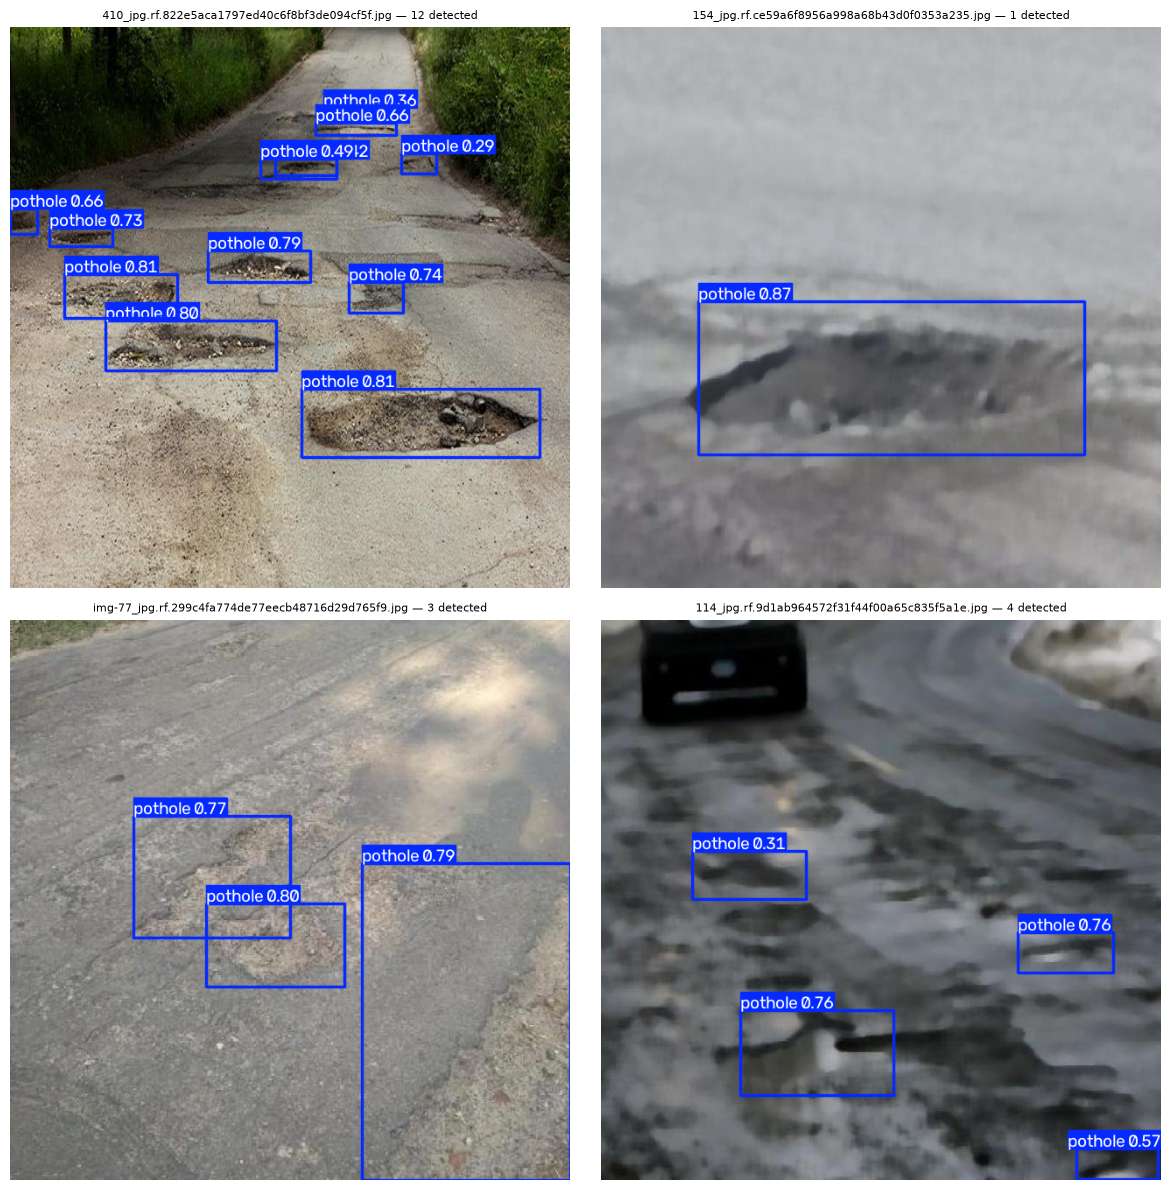

In [3]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

model = YOLO("runs/detect/pothole_runs/v1/weights/best.pt")

test_images_dir = "Potholes-Detection-1/test/images"
sample_files = random.sample(os.listdir(test_images_dir), 4)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for ax, filename in zip(axes.flat, sample_files):
    img_path = os.path.join(test_images_dir, filename)
    results = model(img_path, verbose=False)
    r = results[0]

    annotated = r.plot()  # draws boxes + confidence scores directly onto the image
    ax.imshow(annotated[..., ::-1])  # convert BGR (OpenCV) to RGB (matplotlib)
    ax.set_title(f"{filename} — {len(r.boxes)} detected", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Next steps
- `severity_classifier.ipynb`: classifies each detected pothole as minor / moderate / severe
- `pipeline.ipynb`: runs both models on a photo
- `live.py`: runs both models live on a webcam or video